In [1]:
import statistics
import numpy as np
import scipy.stats
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import seaborn as sns
import statsmodels.api

### IMPORT DATA


In [2]:
bigFive = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
judges = ['Judge 1', 'Judge 2', 'Judge 3', 'Judge 4', 'Judge 5', 'Judge 6', 'Judge 7', 'Judge 8', 'Judge 9', 'Judge 10', 'Judge 11']

#Function taking the judge number 01-11 to return their table of scores
def printJudge(judgeNo):
   # [640rows x 6 columns]
    # Columns: Clip_ID (0), Extraversion (1), Agreeableness (2), Conscientiousness (3), Neuroticism (4), Openness (5)
   return pd.read_csv(f'data/Personality_Scores/Score_0{judgeNo}.csv', delimiter=',')

# [640rows x 4 columns]
#  Columns: Clip_ID (0), Speaker_ID (1), Gender (2), Status (3)
metadata = pd.read_csv('data/metadata.csv')

# Data per Judge
judge1= np.array(printJudge('01'))
judge2= np.array(printJudge('02'))
judge3= np.array(printJudge('03'))
judge4= np.array(printJudge('04'))
judge5= np.array(printJudge('05'))
judge6= np.array(printJudge('06'))
judge7= np.array(printJudge('07'))
judge8= np.array(printJudge('08'))
judge9= np.array(printJudge('09'))
judge10= np.array(printJudge('10'))
judge11= np.array(printJudge('11'))



### DATA MANIPULATION

In [3]:
# ALL INFO FOR A JUDGE FOR ONE GENDER
# Connect Data  parameters --> 'F' or 'M' , judge1 etc.
def splitPerGender(gender, judgeNo):
    judgeData = judgeNo
    listOfGender = np.where(np.array(metadata)[:,2] == gender)[0]
    judgeGenderData = judgeData[listOfGender]
    return (judgeGenderData)


##### Ways to average the scores

In [4]:
#MEAN Scores per clip between judges - 640x5 scores 
def meanScoresPerClip():
    clipIDs = judge1[:,0]
    result = []
    allScores=[]
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        scores = np.array(np.array(printJudge(x))[:,1:])
        allScores.append(scores)
    allScores = np.stack(allScores, axis=0)
    meanScoresPerClip = np.mean(allScores, axis=0)
    result = np.column_stack((np.array(clipIDs), meanScoresPerClip))
    return result


In [5]:
#MEDIAN Scores per clip between judges - 640x5 scores
def medianScoresPerClip():
    clipIDs = judge1[:,0]
    result = []
    allScores=[]
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        scores = np.array(np.array(printJudge(x))[:,1:])
        allScores.append(scores)
    allScores = np.stack(allScores, axis=0)
    medianScoresPerClip = np.median(allScores, axis=0)
    medianScoresPerClip = medianScoresPerClip.astype(int)
    result = np.column_stack((np.array(clipIDs), medianScoresPerClip))
    return result

In [6]:
#MODE Scores per clip between judges
def calcMode(x):
    unique_elements, counts = np.unique(x, return_counts=True)
    mode_index = np.argmax(counts)
    return unique_elements[mode_index]

def modeScoresPerClip():
    clipIDs = judge1[:,0]
    result = []
    allScores=[]
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        scores = np.array(np.array(printJudge(x))[:,1:])
        allScores.append(scores)
    allScores = np.stack(allScores, axis=0)
    allScores = np.transpose(allScores, (1,2,0))
    mode_result = np.apply_along_axis(calcMode, axis=2, arr=allScores)
    result = np.column_stack((np.array(clipIDs), mode_result))
    print(result)


In [7]:
#Mean Scores per clip between judges - ONE GENDER

def meanScoresPerClipGender(gender):
    listOfGender = np.where(np.array(metadata)[:,2] == gender)[0]
    clipIDsForGender = judge1[:,0][listOfGender]
    result = []
    allScores=[]
    i = 0
    while (i<11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        scores = np.array(np.array(printJudge(x))[:,1:][listOfGender])
        allScores.append(scores)
        i = i + 1
    allScores = np.stack(allScores, axis=0)
    meanScoresPerClip = np.mean(allScores, axis=0)
    result = np.column_stack((np.array(clipIDsForGender), meanScoresPerClip))
    return result

def medianScoresPerClipGender(gender):
    listOfGender = np.where(np.array(metadata)[:,2] == gender)[0]
    clipIDsForGender = judge1[:,0][listOfGender]
    result = []
    allScores=[]
    i = 0
    while (i<11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        scores = np.array(np.array(printJudge(x))[:,1:][listOfGender])
        allScores.append(scores)
        i = i + 1
    allScores = np.stack(allScores, axis=0)
    meanScoresPerClip = np.median(allScores, axis=0)
    result = np.column_stack((np.array(clipIDsForGender), meanScoresPerClip))
    return result

## Distribution of data

In [8]:
#Box plot of mean data per clip for each trait

def plotDistributionBox():
    data = meanScoresPerClip()[:,1:]
    df = pd.DataFrame(data,columns=bigFive) 
    plot2 = sns.catplot(kind='box', data=df,  aspect=2, palette=sns.color_palette("Set1"))
    plot2.set(title="Box plot of mean data per clip for each trait", xlabel="Big Five", ylabel = "Personality Perception Scores")
    

In [9]:
# HISTOGRAMS FOR EACH TRAIT FOR DISTRIBUTION OF MEAN SCORES PER CLIP
def distributionHistograms():
    data = meanScoresPerClip()[:,1:]
    df = pd.DataFrame(data,columns=bigFive) 
    display(Markdown('## Distribution of the mean scores per clip for every trait'))
    for i in range(5):
        plot = sns.displot(data[:,i], kde=True)
        plot.set_axis_labels(bigFive[i], "Count")

## Spearman Rank & Spearman Brown 

Spearman Rank Correlation Between judges

* Spearman Rank Correlation - a nonparametric version of the Pearson correlation. It measures the strength and direction of association between two ranked variables.
    * Spearman Rank Correlation is used to measure the correlation between two ranked variables.
    * Measures the monotonic relationship - as one increases does the other increase?
    * The funcion first ranks the data by sorting it in ascending order, then it assigns a rank to based on the position of the data and then replaces the original points with their respective ranks
    * Then the pearson correlation coefficient of the ranks is found
<br><br>
* Output - Spearman rank correlation (rho) and corresponding p-value
    * Rho -> -1 to 1
    * Two-sided p value -> the probability that the observed rho correlation occured by chance. Assuming that the null hypothesis is true - the two variables are uncorrelated. - A low p-value suggests that the observed correlation is statistically significant.
        * p-value < 0.05 - observed correlation is unlikely to be a result of chance
        * large p-value - correlation could plausibly be random chance

Agreement Between judges for a trait using Spearman Rank

In [10]:
#Spearman Rank Correlation Between judges
# Paramaters - trait & True if judge 10 is excluded or False to include
# Return listOfCoefficients - returns the rho values - correlation coefficients of each judge combination
# Return listOfPairs - returns the p values corresponding to each correlation coefficient of each judge combination

def SpearmanRankAllJudgesOneTraitRho(trait, gender):
    sexId = metadata.loc[:,['Clip_ID', 'Gender']].copy()
    
    listOfCoefficients = []
    # listOfPairs=[]
    listOfPvalues = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = pd.DataFrame(printJudge(x))
        withGenderA = pd.merge(judgeA, sexId, on='Clip_ID')
        # print(withGenderA)
        for j in range(i+1,11):
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB =  pd.DataFrame(printJudge(y))
            withGenderB = pd.merge(judgeB, sexId, on='Clip_ID')
            # listOfPairs.append((i+1,j+1))
            if(gender != 'both'):
                judgeA = withGenderA[withGenderA['Gender'] == gender]
                judgeB = withGenderB[withGenderA['Gender'] == gender]
            rho, p = scipy.stats.spearmanr(judgeA[trait].tolist(), judgeB[trait].tolist())
            listOfCoefficients.append(rho)
            listOfPvalues.append(p)
    # print(listOfPairs)
    
    return (listOfCoefficients)

# np.array(SpearmanRankAllJudgesOneTraitRho('Agreeableness', 'F')).shape

Returns a list of [JudgeA, JudgeB, and then one by one the correlation coef & p value for each trait]

In [11]:
# no10 = True in order to exclude judge 10
def SpearmanRankAllJudgesAllTraits():
    listOfPairsAndRank = []
    i=0
    while (i<11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = np.array(printJudge(x))
        j = i+1
        while (j<11):
            row =[]
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = np.array(printJudge(y))
            row.append(i+1)
            row.append(j+1)
            for k in range(1,6):
                row.append(np.array(scipy.stats.spearmanr(judgeA[:,k].tolist(), judgeB[:,k].tolist())))
            listOfPairsAndRank.append(row)
            j = j+1
        i = i+1
    return listOfPairsAndRank


TABLE OF ALL SPEARMAN RANK CORRELATIONS AND CORRESPONDING P VALUES FOR EACH TRAIT FOR ALL 55 UNIQUE COMBINATIONS OF JUDGES

In [12]:
def SpearmanTable():
    data_dict = SpearmanRankAllJudgesAllTraits()
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
    dfSpearman = pd.DataFrame(data_dict, columns=columns) 
    dfSpearman.index = range(1, len(dfSpearman) + 1)
    display(Markdown('## Spearman Rank For each Trait in Rank, P-value pairs'))
    display(dfSpearman)

In [13]:
#Returns a list [JudgeA, JudgeB, and then one by one the correlation coef OR p value for each trait]
def SpearmanRankAllJudgesAllTraitsRorP(RhoORP):
    if (RhoORP=='rho'):
        RorP = 0
    if (RhoORP=='p'):
        RorP = 1
    listOfPairsAndRank = []
    i=0
    while (i<11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = np.array(printJudge(x))
        j = i + 1
        while (j<11):
            row =[]
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = np.array(printJudge(y))
            row.append(i+1)
            row.append(j+1)
            for k in range(1,6):
                row.append(scipy.stats.spearmanr(judgeA[:,k].tolist(), judgeB[:,k].tolist())[RorP])
            listOfPairsAndRank.append(row)
            j = j+1
        i = i+1
    return listOfPairsAndRank

def judgeSkewPlot():
    data = SpearmanRankAllJudgesAllTraitsRorP('p')

    display(Markdown('## Plots of P values (color)per combination of judges (axis)'))

    for i in range(1,6):
        d =  np.array(data)[:,i+1]
        pairs = list(zip(np.array(data)[:,0],np.array(data)[:,1]))
        stringPairs = list(map(lambda x: f'({x[0]}, {x[1]})', pairs))
        y1 = np.array(data)[:,0]
        y2 = np.array(data)[:,1]

        # fig, ax1 = plt.subplots(figsize=(8, 12))
        # ticks = range(len(stringPairs))
        # ax1.scatter(d, stringPairs, color='blue', label='Value')
        # ax1.set_xlabel('P Value')
        # ax1.set_yticks(ticks)
        # ax1.set_yticklabels(y1)
        # ax1.set_ylabel('Judge A', color='blue')
        # ax1.tick_params(axis='y', labelcolor='blue')
        # ax1.set_ylim(min(ticks), max(ticks)+1)
        # ax2 = ax1.twinx()
        # ax2.set_yticks(ticks)
        # ax2.set_yticklabels(y2)
        # ax2.set_ylabel('Judge B', color='red')
        # ax2.tick_params(axis='y', labelcolor='red')
        # plt.grid(True)
        # plt.show()

        # plt.figure(figsize=(8,12))
        # plt.scatter(d,stringPairs)
        # plt.xlabel('P value')
        # plt.ylabel('Pairs')
        # plt.grid(True)
        # plt.show()

        plt.scatter(np.array(data)[:,0], np.array(data)[:,1], c=d, cmap='viridis', s=100, alpha=1)
        cbar = plt.colorbar()
        cbar.set_label('P value')
        plt.xticks(np.arange(1,12))
        plt.yticks(np.arange(2,12))
        plt.title(bigFive[i-1])
        plt.xlabel('Judge A')
        plt.ylabel('Judge B')
        plt.show()

        # fig = plt.figure()
        # ax = fig.add_subplot(111, projection='3d')
        # ax.scatter(np.array(data)[:,0], np.array(data)[:,1], d)
        # ax.set_xlabel('Judge A')
        # ax.set_ylabel('Judge B')
        # ax.set_zlabel('P value')
        # plt.show()

# judgeSkewPlot()


In [14]:
#Bonferroni Correction on Spearman Rank of judge pairs

#Parameter - method - 'bonferroni' , 'sidak', 'fdr_bh', 
def spearmanJudgesCorrection(method,returnInfo):
    data = SpearmanRankAllJudgesAllTraitsRorP("p")
    corrected = np.zeros((55,7))
    
    corrected[:,0:2] = np.array(data)[:,0:2]
    corrected[:,0:2].astype(int)
    correctedAlphaBonferroni = statsmodels.stats.multitest.multipletests(np.array(data)[:,2], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[3]
    correctedAlphaSidak = statsmodels.stats.multitest.multipletests(np.array(data)[:,2], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[2]
    if ((returnInfo == 'alpha') & (method=='bonferroni')):
        # print( "Bonferroni alpha: ")
        return correctedAlphaBonferroni
    if ((returnInfo == 'alpha') & (method=='sidak')):
        # print( "Sidak alpha: ")
        return correctedAlphaSidak
    for i in range(2,7):
        corrected[:,i] = (statsmodels.stats.multitest.multipletests(np.array(data)[:,i], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[1])
    return corrected

def spearmanJudgesCorrectionTable(method):
    display(Markdown(f'### {method} Correction p values of Spearman Rank between Genders For each judge'))
    corrected = spearmanJudgesCorrection(method,'P Values')
    correctionTable = pd.DataFrame(corrected, columns= np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0))
    correctionTable['JudgeA'] = correctionTable['JudgeA'].astype(int)
    correctionTable['JudgeB'] = correctionTable['JudgeB'].astype(int)
    correctionTable.index = range(1, len(corrected) + 1)
    display (correctionTable)

# spearmanJudgesCorrection('bonferroni', 'alpha')


In [15]:
## T tests over the Spearman p values

def tTestPvalues():
    resultPvalue=[]
    import itertools
    data = SpearmanRankAllJudgesAllTraitsRorP('p')
    tStatistic =[]
    pValue = []

    # how can i do it since it takes two arrays and i only have 1 array of the p values
    for i in range(1,6):
        d =  np.array(data)[:,i+1]
        pairs = list(itertools.combinations(d, 2))
        first_elements = [pair[0] for pair in pairs]
        second_elements = [pair[1] for pair in pairs]
        t, p = scipy.stats.ttest_ind(second_elements, first_elements)
        tStatistic.append(t)
        pValue.append(p)
    display(Markdown('## T test of the p values from spearman'))
    resultPvalue.append(pValue)
    df = pd.DataFrame(resultPvalue, columns=bigFive)
    df.index = ['P value']
    display (df)
    # return (resultPvalue)



In [16]:
# Table of Average Spearman rank per trait

def SpearmanAverageTable(averageType):
    data_dict = SpearmanRankAllJudgesAllTraits()
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
    data = pd.DataFrame(data_dict, columns=columns) 
    # data.index = range(1, len(dfSpearman) + 1)  
    averagesPerTrait = []
    for trait in bigFive:
        # print(data[trait])
        if (averageType == "Mode"):
            averagesPerTrait.append(scipy.stats.mode(data[trait].tolist(),axis=0)[0][0])
        if (averageType == "Mean"):          
            averagesPerTrait.append(data[trait].mean())
        if (averageType == "Median"):    
            df = pd.DataFrame(data[trait].tolist(),columns=['rho','p'])
            averagesPerTrait.append((df['rho'].median(),df['p'].median()))
    dfAverages = pd.DataFrame(averagesPerTrait,columns=['Spearman Rank','P value'])
    dfAverages.index = bigFive
    display(Markdown(f'#### {averageType} Average Spearman Rank per Trait (Rank & P-value)'))
    display(dfAverages)
    return(dfAverages)

# SpearmanAverageTable('Median')
# SpearmanAverageTable('Mean')
# SpearmanAverageTable('Mode')
# SpearmanAverageTable('Mode')


In [17]:
# Function running the different spearman averages for Judge Agreement & returning conclusions

        
def judgeAgreementResults(averageMethod, alpha):
    data = SpearmanAverageTable(averageMethod)
    display(Markdown(f'#### Statistical Significance for {averageMethod} Spearman Rank'))
    for i in range (5):
        value = data['P value'][bigFive[i]]
        sig = ''
        if (value > alpha):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")


# judgeAgreementResults('Mean',0.05)
# judgeAgreementResults('Median',0.05)


In [18]:
# ?????????
def SpearmanAverageTableCorrection(method, averageType):
    meanAveragesPerTrait = []
    medianAveragesPerTrait = []
    for i in range(2,7):   
        x = spearmanJudgesCorrection(method, 'P Values')
        meanAveragesPerTrait.append(x[:,i].mean())
        df = pd.DataFrame(x[:,i],columns=['p'])
        medianAveragesPerTrait.append(df['p'].median())
    if (averageType == 'mean'):
        averagesPerTrait = meanAveragesPerTrait
    if (averageType == 'median'):
        averagesPerTrait = medianAveragesPerTrait
    dfAverages = pd.DataFrame(averagesPerTrait,columns=['P-value'])
    dfAverages.index = bigFive
    display(Markdown(f'## Post {method} Average Spearman Rank per Trait (Rank & P-value)'))
    display(dfAverages)
    return dfAverages


# SpearmanAverageTableCorrection('bonferroni','mean')
# SpearmanAverageTableCorrection('bonferroni','median')
# SpearmanAverageTableCorrection('sidak','mean')
# SpearmanAverageTableCorrection('sidak','median')



In [19]:
def judgeAgreementResultsFDR(averageMethod, alpha):
    data = SpearmanAverageTableCorrection('fdr_bh',averageMethod)
    display(Markdown(f'#### Statistical Significance for {averageMethod} Spearman Rank'))
    for i in range (5):
        # print(data)
        value = data['P-value'][bigFive[i]]
        sig = ''
        if (value > alpha):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")


# judgeAgreementResultsFDR('median', 0.05)

## Spearman Brown Correlation

* Evaluates test reliability
* used when the length of a test is changed and you want to see if reliability has increased? -> original test having 10 questions and new having 15.
* shows an estimate of how much the test reliability will change if the number of items/questions in the test is altered.
<br>
<br>
* In this case
    * how the number of judges affects the reliability

* Parameters
    * n - new test Length - new length/no of questions
    * R old - spearman rank rho

* SPLIT HALF RELIABILITY
    * Reliability Coefficient (R)
        * Calculate correlation between two halves 
            * female vs male? or judges?
                * the two halves must be even.
    * Take a random sample of half of the items & run analysis between the two halves?

* Spearman Brown formula 
    * Rnew = 2R/1+R


* So high correlation = high reliability.
* Usually over 0.7 it is considered good.

In [20]:
# Getting the spearman brown for a specific trait for a specific number of judges
#Using the mean of rho values for each trait
def spearmanBrown(trait, numberOfjudges, gender):
    old = np.mean(SpearmanRankAllJudgesOneTraitRho(trait, gender))
    return (old, (numberOfjudges * old / (1 + (numberOfjudges - 1) * old)))

def SpearmanBrownTable(gender):
    number = 11 
    spearmanBrownPerTrait = []
    for trait in bigFive:       
        spearmanBrownPerTrait.append(spearmanBrown(trait,number,gender))
    dfBrown = pd.DataFrame(spearmanBrownPerTrait, columns = ['Correlation', 'Spearman Brown'])
    dfBrown.index = bigFive
    display(Markdown('#### Spearman Brown per Trait (Correlation (Reliability old) & Spearman Brown (new))'))
    display(dfBrown)
    return(dfBrown)

#Using the median of rho values for each trait
def spearmanBrownMedian(trait, numberOfjudges, gender):
    old = np.median(SpearmanRankAllJudgesOneTraitRho(trait, gender))
    return (old, (numberOfjudges * old / (1 + (numberOfjudges - 1) * old)))


def SpearmanBrownTableMedian(gender):
    number = 11
    spearmanBrownPerTrait = []
    for trait in range(1,6):       
        spearmanBrownPerTrait.append(spearmanBrownMedian(trait,number,gender))
    # print(spearmanBrownPerTrait)
    dfBrown = pd.DataFrame(spearmanBrownPerTrait, columns = ['Correlation', 'Spearman Brown'])
    dfBrown.index = bigFive
    display(Markdown('#### Spearman Brown per Trait (Correlation (Reliability old) & Spearman Brown (new))'))
    display(dfBrown)

# SpearmanBrownTable()
# SpearmanBrownTableMedian()


def SpearmanBrownResults(gender):
    data = SpearmanBrownTable(gender)
    values = data['Spearman Brown']
    rho = data['Correlation']
    for trait in bigFive:
        if (values[trait] > 0.7):
            print(trait, ' is GOOD \n     rho:', rho[trait])
        if (values[trait] > 0.5):
            print(trait, ' is FAIR \n     rho:', rho[trait])
        else:
            print(trait, ' is BAD \n     rho:', rho[trait])



## CORRELATION BETWEEN GENDERS

In [21]:
#Pearson Correlation Histograms

#ALL RECORDINGS FROM ALL JUDGES (INCLUDING DUPLICATES) FOR A GENDER
def allJudgesOneGender(gender):
    total = splitPerGender(gender, judge1)
    i=1
    while (i<11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        total = np.concatenate((total, splitPerGender(gender,np.array(printJudge(x)))), axis=0)
        i=i+1
    return total
    
# print(allJudgesOneGender('F'))

### PER GENDER



In [22]:
#Pearson Correlation Coefficients Per trait per GENDER FOR THE FIRST 1507 NUMBER OF MALE INPUTS

def corrPerTraitBetweenGenders():
    listOfCoefficients = []
    i=1
    while i <6:
        listOfCoefficients.append(np.corrcoef(np.array(allJudgesOneGender('M',False)[:1507,i]).tolist(), np.array(allJudgesOneGender('F',False)[:,i]).tolist())[0:1][0][1])
        i = i + 1
    return (listOfCoefficients)

# print(corrPerTraitBetweenGenders())


### Correlation between 55 unique combinations of judges for a specific trait
### FOR ONE GENDER

### Pearson Correlation per trait for only one gender - over all judges

In [23]:
#Correlation between judges for a trait only for ONE specific gender

def corrAllJudgesOneGenderOneTrait(trait, gender):
    listOfCoefficients = []
    listOfPairs = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = splitPerGender(gender,np.array(printJudge(x)))
        for j in range(i+1,11):
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = splitPerGender(gender,np.array(printJudge(y)))
            # listOfPairs.append((i+1,j+1))
            listOfCoefficients.append(np.corrcoef(judgeA[:,trait].tolist(), judgeB[:,trait].tolist())[0:1][0][1])
    # print(listOfPairs)
    return (listOfCoefficients)

# corrAllJudgesOneGenderOneTrait(2,'M').shape


In [24]:
def corrAllJudgesOneGenderAllTraitWithP(gender, onlyP):
    listOfCoefficients = []
    listOfPairs = []
    listOfPairsAndCorr = []
    listOfPairsAndPs = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = splitPerGender(gender,np.array(printJudge(x)))
        for j in range(i+1,11):
            row = []
            row2 = []
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = splitPerGender(gender,np.array(printJudge(y)))
            # listOfPairs.append((i+1,j+1))
            row.append(i+1)
            row2.append(i+1)
            row.append(j+1)
            row2.append(j+1)
            for k in range(1,6):
                listOfCoefficients.append(scipy.stats.pearsonr(judgeA[:,k].tolist(), judgeB[:,k].tolist()))
                row2.append(scipy.stats.pearsonr(judgeA[:,k].tolist(), judgeB[:,k].tolist())[1])
                row.append(np.array(scipy.stats.pearsonr(judgeA[:,k].tolist(), judgeB[:,k].tolist())))
            listOfPairsAndPs.append(row2)
            listOfPairsAndCorr.append(row)
    # print(listOfPairs)
    # return (listOfCoefficients)
    if (onlyP==True):
        return listOfPairsAndPs
    else:
        return listOfPairsAndCorr

# np.array(corrAllJudgesOneGenderAllTraitWithP('F',True)).shape


In [25]:
def SpearmanRankAllJudgesAllTraitsPerGender(gender):
    listOfPairsAndRank = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = splitPerGender(gender,np.array(printJudge(x)))
        for j in range(i+1,11):
            row =[]
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = splitPerGender(gender,np.array(printJudge(y)))
            row.append(i+1)
            row.append(j+1)
            for k in range(1,6):
                row.append(scipy.stats.spearmanr(judgeA[:,k].tolist(), judgeB[:,k].tolist()))
            listOfPairsAndRank.append(row)
    return listOfPairsAndRank

### Spearman Rank per trait for only one gender - over all judges

In [26]:
## TABLE FOR EACH TRAIT FOR THE SPEARMAN RANK OF ALL 55 JUDGES FOR FEMALE ONLY

def oneGenderOnlySpearman(gender):
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
    if (gender=='male'):
        dfGender  = pd.DataFrame(SpearmanRankAllJudgesAllTraitsPerGender('M'), columns=columns) 
    if (gender=='female'):
        dfGender = pd.DataFrame(SpearmanRankAllJudgesAllTraitsPerGender('F'), columns=columns) 
    print(len(dfGender))
    dfGender.index = range(1, len(dfGender) + 1)
    display(Markdown(f'## Spearman Rank For {gender} For each Trait in Coefficient, P-value pairs'))
    display(dfGender)
    return dfGender

# oneGenderOnlySpearman('female')
# oneGenderOnlySpearman('male')


In [27]:
# Table of Average of the spearman rank per trait

def maleOnlyAverageSpearman(averageType):
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
    dfMale  = pd.DataFrame(SpearmanRankAllJudgesAllTraitsPerGender('M'), columns=columns) 
    averagesPerTraitMale = []
    for trait in bigFive:   
        if (averageType=="Mean"):
            df = pd.DataFrame(dfMale[trait].tolist(),columns=['rho','p'])
            averagesPerTraitMale.append((df['rho'].median(),df['p'].mean()))
        if (averageType=="Mode"):
            averagesPerTraitMale.append(scipy.stats.mode(dfMale[trait].tolist(),axis=0)[0][0])
        if (averageType=="Median"):
            df = pd.DataFrame(dfMale[trait].tolist(),columns=['rho','p'])
            averagesPerTraitMale.append((df['rho'].median(),df['p'].median()))
    dfAveragesMale = pd.DataFrame(averagesPerTraitMale,columns=['Spearman Rho','P-value'])
    dfAveragesMale.index = bigFive
    display(Markdown(f'#### {averageType} Average Spearman Rank For Male For each Trait in Coefficient, P-value pairs'))
    display (dfAveragesMale)
    return dfAveragesMale


def femaleOnlyAverageSpearman(averageType):
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
    dfFemale  = pd.DataFrame(SpearmanRankAllJudgesAllTraitsPerGender('F'), columns=columns) 
    averagesPerTraitFemale = []
    for trait in bigFive:   
        if (averageType=="Mean"):
            df = pd.DataFrame(dfFemale[trait].tolist(),columns=['rho','p'])
            averagesPerTraitFemale.append((df['rho'].median(),df['p'].mean()))
        if (averageType=="Mode"):
             averagesPerTraitFemale.append(scipy.stats.mode(dfFemale[trait].tolist(),axis=0)[0][0])
        if (averageType=="Median"):
            df = pd.DataFrame(dfFemale[trait].tolist(),columns=['rho','p'])
            averagesPerTraitFemale.append((df['rho'].median(),df['p'].median()))
        # if (averageType=="Median"):
            #  averagesPerTraitFemale.append(statistics.median(dfFemale[trait].tolist()))
    dfAveragesFemale = pd.DataFrame(averagesPerTraitFemale,columns=['Spearman Rho','P-value'])
    dfAveragesFemale.index = bigFive
    display(Markdown(f'#### {averageType} Average Spearman Rank For Female For each Trait in Coefficient, P-value pairs'))
    display(dfAveragesFemale)
    return dfAveragesFemale

def oneGenderAverageSpearmanResults(averageType,gender,alpha):
    if (gender == 'male'):
        data = maleOnlyAverageSpearman(averageType)
    else:
        data = femaleOnlyAverageSpearman(averageType)
    display(Markdown(f'#### Statistical Significance for {averageType} Spearman Rank Only for {gender}'))
    for i in range (5):
        value = data['P-value'][bigFive[i]]
        sig = ''
        if (value > alpha):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")
    
# oneGenderAverageSpearmanResults('Median', 'male', 0.05)

Correlation per trait - between genders of each judge
* how is this judge stereotyping?

In [28]:
# display(Markdown('# Comparisons between gender using t-tests'))

## T test
* DIFFERENT SIZES OF THE TWO SAMPLES (female & female) BUT same variance
* Two/Independent Sample T-test
    * checks whether the unknown population means of a given pair of groups are equal - determine if the samples are different from each other
    * different people providing scores for each group
    * Results:
        * t-statistic -> larger t-statistic = greater difference between the groups
        * p-value: if <0.05 then reject null hypothesis - there is a difference between the mean of male & female
  

In [29]:
# T test Table for every judge individually

def tTestIndividualJudgeTable():
    data = []
    for i in range(11):
        judgeTraits=[]
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judge = np.array(printJudge(x))
        for j in range(1,6):
            tStatistic, pValue = scipy.stats.ttest_ind(a=splitPerGender('F',judge)[:,j].tolist(), b=splitPerGender('M',judge)[:,j].tolist(), equal_var=True)
            result = [tStatistic, pValue]
            judgeTraits.append(result)
        data.append(judgeTraits)

    dfTtest = pd.DataFrame(data,columns=bigFive)
    dfTtest = pd.DataFrame(data,columns=bigFive)
    dfTtest.index = ['Judge1', 'Judge2', 'Judge3', 'Judge4','Judge5', 'Judge6','Judge7', 'Judge8','Judge9', 'Judge10','Judge11']
    display(Markdown('## T-test results between Genders For each judge individually per Trait in t-statistic, P-value pairs'))
    display (dfTtest)

# tTestIndividualJudgeTable()

In [30]:
# Effect size - how meaningful the relationship between variables or the difference between group is.

from math import sqrt
def cohensD(a,b):
    return (statistics.mean(a) - statistics.mean(b)) / (sqrt((statistics.stdev(a) ** 2 + statistics.stdev(b) ** 2) / 2))

data = []
for i in range(11):
    judgeTraits=[]
    if (i<9):
        x = '0' + str(i+1)
    else:
        x = str(i+1)
    judge = np.array(printJudge(x))
    for j in range(1,6):
        judgeTraits.append(cohensD(splitPerGender('F',judge)[:,j].tolist(), splitPerGender('M',judge)[:,j].tolist()))
    data.append(judgeTraits)

# print(np.array(data).shape)

dfCohens = pd.DataFrame(data,columns=bigFive)
dfCohens.index = ['Judge1', 'Judge2', 'Judge3', 'Judge4','Judge5', 'Judge6','Judge7', 'Judge8','Judge9', 'Judge10','Judge11']
# display(Markdown('## Cohen\'s D results between Genders For each judge individually per Trait in t-statistic, P-value pairs'))
# display (dfCohens)


TABLE OF T TEST VALUES FOR WHOLE DATA OF MALE VS FEMALE INCLUDING DUPLICATE
* CLIPS FROM ALL JUDGES
* Judge independent


In [31]:
#TABLE OF T TEST VALUES FOR WHOLE DATA OF MALE VS FEMALE INCLUDING DUPLICATE CLIPS FROM ALL JUDGES

def tTestAllMalevsAllFemaleCorrection(method):
    data = tTestAllMalevsAllFemale()['P-value']
    if (method=='bonferroni'):
        alphaB= (statsmodels.stats.multitest.multipletests(data, alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[3])
        return alphaB
    if (method=='sidak'):
        alphaS= (statsmodels.stats.multitest.multipletests(data, alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[2])
        return alphaS

def tTestAllMalevsAllFemale():
    data=[]
    for j in range(1,6):
        data.append(scipy.stats.ttest_ind(a=allJudgesOneGender('F')[:,j].tolist(), b=allJudgesOneGender('M')[:,j].tolist(), equal_var=True))
    df = pd.DataFrame(data,columns=['T-statistic','P-value'])
    df.index = bigFive
    # print(Markdown('### T-test results between Genders For each Trait using all judges\' data in t-statistic, P-value pairs'))
    return df



In [32]:
def tTestAllDataResults(p):
    data = tTestAllMalevsAllFemale()
    display(Markdown('#### Statistical Significance for t-test over all male vs all female'))
    for i in range (5):
        value = data['P-value'][bigFive[i]]
        sig = ''
        if (value > p):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")

# tTestAllDataResults(0.05)

### CORRECTION

- Used to account for inflated Type I error 
    - the higher the chance for a false positive
- Familywise Error Rate
    - the probability of 1+ Type I errors in a set of comparisons.

#### Bonferroni
- Type of multiple comparison test used in statistical analysis. 
- A statistical test used to reduce instances of false positives
- The p value of each test should be equal to its aplha divided by the number of tests.  
- Controls the probebility of at least making one false conclusion
- Most common use: If I have a list of t-tests and a significant result for even one of them that rejects the null hypothesis
    - Use Bonferroni correction

statsmodels.stats.multitest.multipletests(pvals, alpha=0.05, method='hs', maxiter=1, is_sorted=False, returnsorted=False)
- pvals - 1D array of p values
- method = 'bonferroni'
        

#### Sidak
- A simple method of controlling family-wise error rate
- More powerful that Bonferroni
- Assumes each comparison is independent from the others
- considers the number of tests performed and then adjusts the alpha.

#### False discovery rate correction
- Alternative to Bonferroni
- Controls for a low proportion of false positives
- Methods
    - Benjamini-Hochberg
        - controls for the expected proprotion of false discoveries among all disoveries 
    - Benjamini-Yekutieli
        - Stricted correction BH when the tests are dependent or have strong positive correlation


In [33]:
# CORRECTION ON T TESTS PER JUDGE (M vs F)
# TO USE FOR tTestIndividualJudgeTable p values

#PARAMETERS: 'bonferroni', 'sidak', 'fdr_bh','fdr_by'
def genderComparisonperJudgeCorrection(method, returnInfo):
    judgeNo = 0
    data = []
    pValues = []
    while (judgeNo<11):
        judgeP=[]
        judgeTraits=[]
        if (judgeNo<9):
            x = '0' + str(judgeNo+1)
        else:
            x = str(judgeNo+1)
        judge = np.array(printJudge(x))
        for j in range(1,6):
            tStatistic, pValue = scipy.stats.ttest_ind(a=splitPerGender('F',judge)[:,j].tolist(), b=splitPerGender('M',judge)[:,j].tolist(), equal_var=True)
            result = [tStatistic, pValue]
            judgeP.append(pValue)
            judgeTraits.append(result)
        data.append(judgeTraits)
        pValues.append(judgeP)
        judgeNo = judgeNo + 1

    dfTtest = pd.DataFrame(data,columns=bigFive)
    pValueTotal = pd.DataFrame(pValues,columns=bigFive)
    # print(pValueTotal[bigFive[1]])

    display(Markdown(f'### {method} Correction p values of T-test results between Genders For each judge'))
    corrected = []
    if ((returnInfo == 'alpha') & (method=='bonferroni')):
        alphaB = (statsmodels.stats.multitest.multipletests(pValueTotal[bigFive[1]], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[3])
        return alphaB
    if ((returnInfo == 'alpha') & (method=='sidak')):
        alphaS = (statsmodels.stats.multitest.multipletests(pValueTotal[bigFive[1]], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[2])
        return alphaS
    for trait in bigFive:
        corrected.append(statsmodels.stats.multitest.multipletests(pValueTotal[trait], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[1])
    
    correctionTable = pd.DataFrame(corrected, columns=judges)
    correctionTable.index = bigFive
    return (correctionTable)



# genderComparisonperJudgeCorrection('bonferroni', 'alpha')


TABLE OF T TEST VALUES FOR AVERAGE CLIPS OF MALE VS FEMALE 
* AVERAGE PER CLIP OVER ALL JUDGES
* Judge independent

In [34]:
#TABLE OF T TEST VALUES FOR MEAN PER CLIP OF MALE VS FEMALE

def tTestAveragePerClipGender(averageType):
    if (averageType=="Mean"):
        averageClips = meanScoresPerClip()
    if (averageType=="Mode"):
        averageClips = modeScoresPerClip()
    if (averageType=="Median"):
        averageClips = medianScoresPerClip()
    data=[]
    for j in range(1,6):
        female = averageClips[np.where(np.array(metadata)[:,2] == 'F')[0]]
        male = averageClips[np.where(np.array(metadata)[:,2] == 'M')[0]]
        data.append(scipy.stats.ttest_ind(a=female[:,j].tolist(), b=male[:,j].tolist(), equal_var=True))

    df = pd.DataFrame(data,columns=['T-statistic','P-value'])
    df.index = bigFive
    # display(Markdown(f'### T-test results between Genders For each Trait using {averageType} per clip in t-statistic, P-value pairs'))
    return df

# tTestAveragePerClipGender("Mean")


def tTestAveragePerClipGenderCorrection(method):
    data = tTestAveragePerClipGender('Mean')['P-value']
    # ??????
    if (method=='bonferroni'):
        alphaB= (statsmodels.stats.multitest.multipletests(data, alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[3])
        return alphaB
    if (method=='sidak'):
        alphaS= (statsmodels.stats.multitest.multipletests(data, alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[2])
        return alphaS

def tTestAveragePerClipGenderResults(averageType,p):
    data = tTestAveragePerClipGender(averageType)
    display(Markdown(f'#### Statistical Significance for t-test of  {averageType} average per clip'))
    for i in range (5):
        value = data['P-value'][bigFive[i]]
        sig = ''
        if (value > p):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")


# tTestAveragePerClipGenderResults('Mean',0.05)
        
# tTestAveragePerClipGenderCorrection('bonferroni')

In [35]:
#Correlation For per trait between the genders of each judge?????

#Mean female & mean male for one judge
def meanGenderScoresPerJudge(judge):
    result={}
    clipIDsF = splitPerGender('F',judge)[:,0]
    clipIDsM = splitPerGender('M',judge)[:,0]
    fScores= splitPerGender('F', judge)[:,1:]
    mScores=splitPerGender('M', judge)[:,1:]
    meanScoreM = np.mean(mScores, axis=0)
    meanScoreF = np.mean(fScores, axis=0)
    result['F'] = meanScoreF
    result['M'] = meanScoreM
    return (result)

# print(meanGenderScoresPerJudge(judge1))

#correlation coefficient for one judge, between male and female.
#for 
def corrPerTraitBetweenGendersOnejudge(judge):
    femaleScores = meanGenderScoresPerJudge(judge)['F']
    maleScores = meanGenderScoresPerJudge(judge)['M']
    # print(femaleScores)
    # print(maleScores)
    # print(np.corrcoef(np.array(femaleScores).tolist(), np.array(maleScores).tolist()))
    # female = splitPerGender('F',judge)
    # male =splitPerGender('M',judge)
    listOfCoefficients = []
    i=1
    while i <6:
        listOfCoefficients.append(np.corrcoef(femaleScores.tolist(), maleScores.tolist())[0:1][0][1])
        i = i + 1
    return (listOfCoefficients)

# print(corrPerTraitBetweenGendersOnejudge(judge1))

# print(splitPerGender('F',judge1)[:,1:])



## Plot with average per clip for female vs male per trait

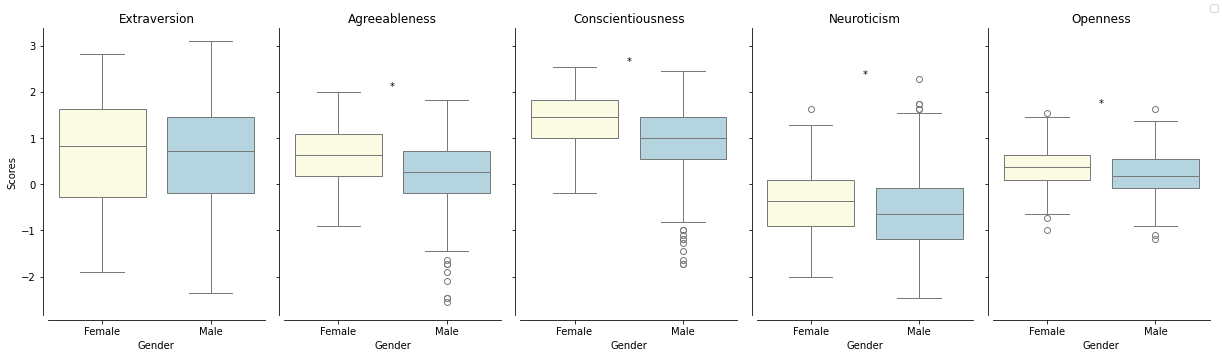

In [54]:


def boxPlotAveragePerClipGender(averageType,alpha):
    display(Markdown('## Plot with average per clip for female vs male per trait'))
    fig, axes = plt.subplots(1, 5, figsize=(17, 5), sharey=True)

    for i in range(1, 6):
        
        if averageType == 'median':
            dfF = np.array(medianScoresPerClipGender('F')[:, i].tolist())
            dfM = np.array(medianScoresPerClipGender('M')[:, i].tolist())
        elif averageType == 'mean':
            dfF = np.array(meanScoresPerClipGender('F')[:, i].tolist())
            dfM = np.array(meanScoresPerClipGender('M')[:, i].tolist())

        colorsdfF = ['lightyellow'] * len(dfF)  
        colorsdfM = ['lightblue'] * len(dfM)  

        combinedData = np.concatenate((dfF, dfM), axis=0)
        labels = ['Female'] * len(dfF) + ['Male'] * len(dfM)

        df = pd.DataFrame({'Scores': combinedData, 'Gender': labels})

        sns.boxplot(x='Gender', y='Scores', data=df, ax=axes[i-1], hue='Gender', palette=[colorsdfF[0], colorsdfM[0]])
        sns.despine(offset = 5)

        t, p = scipy.stats.ttest_ind(dfF, dfM)
        if (p<alpha):
            star = '*'
        else:
            star =''

        max =  np.max(combinedData)
        axes[i-1].text(0.5, max, star, ha='center', va='bottom')
        axes[i-1].set_title(f'{bigFive[i-1]}')

    # Create a legend
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right')

    plt.tight_layout()
    plt.show()
